                    TOWN  LATITUDE  LONGITUDE  TownCode
0    Bukowina Tatrzanska   49.3431    20.1099         1
1                 Tylicz   49.3982    21.0276         2
2              Tylmanowa   49.4952    20.4043         3
3              Nowy Sacz   49.6249    20.6917         4
4               Jordanow   49.6557    19.8143         5
..                   ...       ...        ...       ...
162            Jeziorany   53.9742    20.7462       163
163               Orneta   54.1124    20.1152       164
164               Dygowo   54.1311    15.7191       165
165               Gdansk   54.3851    18.6218       166
166            Wejherowo   54.6002    18.2500       167

[167 rows x 4 columns]

Columns Used:
['LATITUDE', 'LONGITUDE', 'AVG_NOISE_LVL', 'Duration_hours', 'Risk_Level', 'TownCode']

Pearson Correlation Matrix
                LATITUDE  LONGITUDE  AVG_NOISE_LVL  Duration_hours  \
LATITUDE        1.000000  -0.016056      -0.172165       -0.030281   
LONGITUDE      -0.016056   1.00000

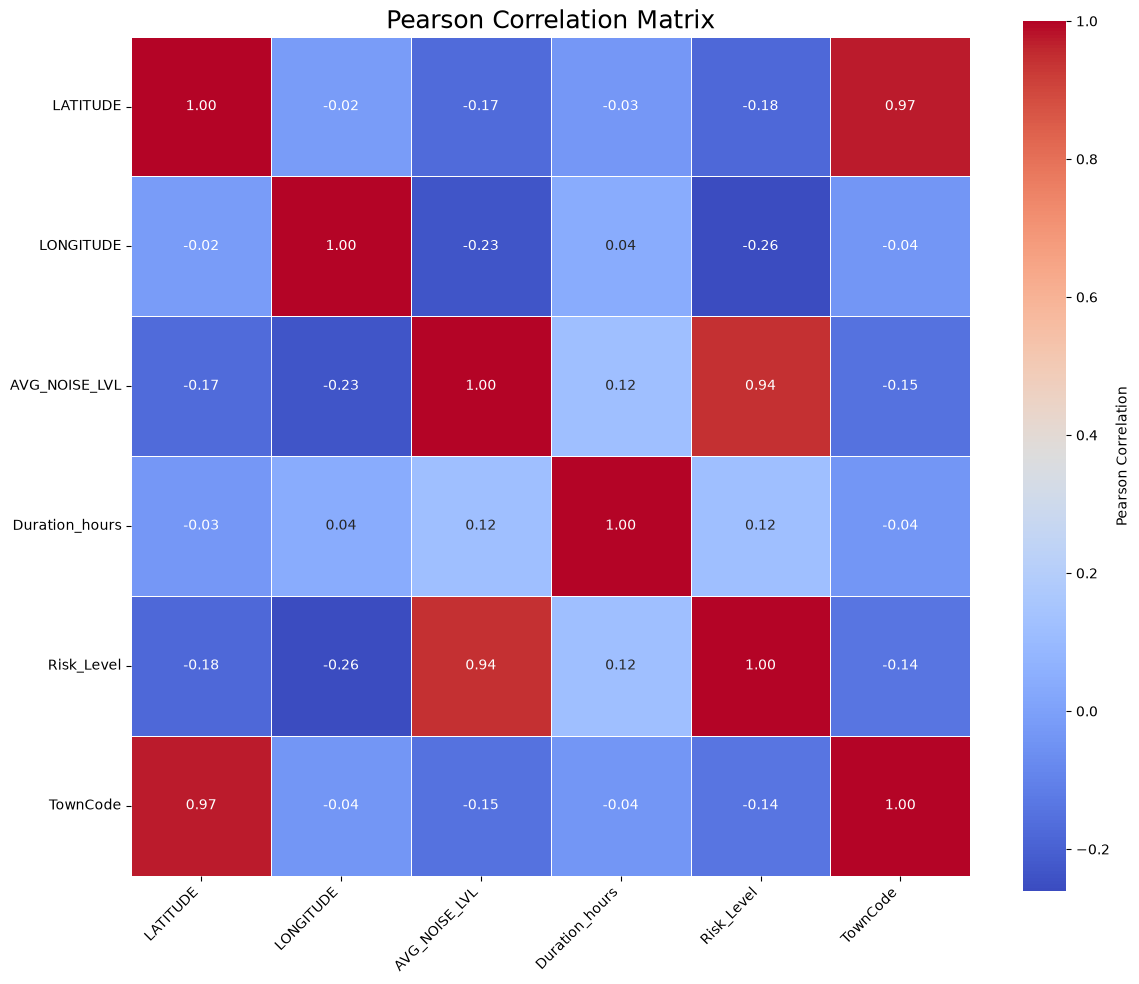


Spearman Correlation Matrix
                LATITUDE  LONGITUDE  AVG_NOISE_LVL  Duration_hours  \
LATITUDE        1.000000  -0.055995      -0.165555       -0.028010   
LONGITUDE      -0.055995   1.000000      -0.232632        0.040452   
AVG_NOISE_LVL  -0.165555  -0.232632       1.000000        0.134849   
Duration_hours -0.028010   0.040452       0.134849        1.000000   
Risk_Level     -0.187485  -0.247619       0.748866        0.132502   
TownCode        0.989061  -0.096892      -0.143259       -0.036998   

                Risk_Level  TownCode  
LATITUDE         -0.187485  0.989061  
LONGITUDE        -0.247619 -0.096892  
AVG_NOISE_LVL     0.748866 -0.143259  
Duration_hours    0.132502 -0.036998  
Risk_Level        1.000000 -0.146820  
TownCode         -0.146820  1.000000  


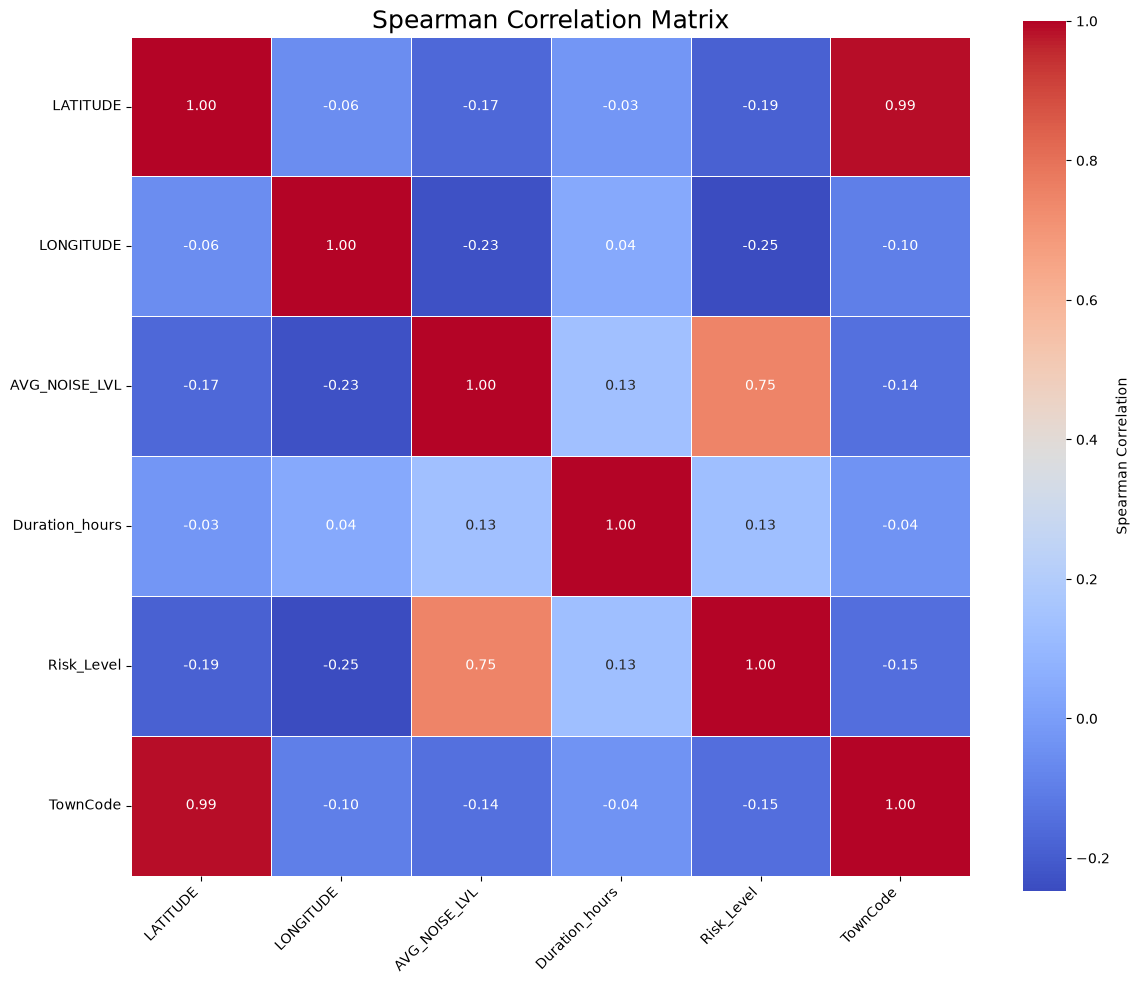

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================
# Enter your Excel file path
# ==========================
file_path = r"Road_noise_measurements_filled (1).xlsx"

# ==========================
# Read Excel Sheet
# ==========================
df = pd.read_excel(file_path, sheet_name="Road_noise_measurements")

# ==========================================================
# Create TownCode based on Latitude and Longitude
# ==========================================================

# Get one coordinate pair for each town
town_locations = (
    df.groupby("TOWN")[["LATITUDE", "LONGITUDE"]]
      .first()
      .reset_index()
)

# Sort by Latitude first, then Longitude
town_locations = town_locations.sort_values(
    by=["LATITUDE", "LONGITUDE"],
    ascending=[True, True]
).reset_index(drop=True)

# Assign TownCodes starting from 1
town_locations["TownCode"] = range(1, len(town_locations) + 1)

# Merge TownCode back into original dataset
df = df.merge(
    town_locations[["TOWN", "TownCode"]],
    on="TOWN",
    how="left"
)

print(town_locations)
# ==========================================================
# Convert Risk Level to Numeric
# ==========================================================

risk_mapping = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

df["Risk_Level"] = df["Risk_Level"].map(risk_mapping)

# ==========================================================
# Remove unwanted columns
# ==========================================================

remove_cols = [
    "ID_MEASURING_RECORD",
    "MEU",
    "Cumulative_MEU"
]

df = df.drop(columns=[c for c in remove_cols if c in df.columns])

# ==========================================================
# Select only numeric columns
# ==========================================================

numeric_df = df.select_dtypes(include="number")

print("\nColumns Used:")
print(numeric_df.columns.tolist())

# ==========================================================
# PEARSON CORRELATION MATRIX
# ==========================================================

pearson_corr = numeric_df.corr(method="pearson")

print("\nPearson Correlation Matrix")
print(pearson_corr)

pearson_corr.to_excel("Pearson_Correlation_Matrix.xlsx")

plt.figure(figsize=(12,10))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar_kws={"label":"Pearson Correlation"}
)

plt.title("Pearson Correlation Matrix", fontsize=18)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==========================================================
# SPEARMAN CORRELATION MATRIX
# ==========================================================

spearman_corr = numeric_df.corr(method="spearman")

print("\nSpearman Correlation Matrix")
print(spearman_corr)

spearman_corr.to_excel("Spearman_Correlation_Matrix.xlsx")

plt.figure(figsize=(12,10))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar_kws={"label":"Spearman Correlation"}
)

plt.title("Spearman Correlation Matrix", fontsize=18)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()